In [1]:
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *

In [2]:
sqy2h_outputs_dir = "../3_outputs/sqY2H"
metadata_outputs_dir = "../../../1_allele_collection/3_outputs"
integrative_inputs = "../../../3_integrated_assay_results/1_inputs"

In [3]:
# process metadata
metadata = pl.DataFrame(pd.read_csv(f"{metadata_outputs_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad.tsv", sep="\t"))
mut_cols = ["mutation_id_rc4", "mutation_id_cegs2", "mutation_id_edgotyping3"]
id_vars = [col for col in metadata.columns if col not in mut_cols]
# metadata = metadata.unpivot(index=id_vars, 
#                             on=mut_cols,
#                             variable_name="mutation_collection",
#                             value_name="mut_id")

priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
metadata = metadata.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
)

In [4]:
# merge scores with metadata
scores = pl.read_csv(f"{sqy2h_outputs_dir}/5_variant_perturbation_scores_automated_summed.csv").with_columns(
    pl.col("db_orf_id").cast(pl.Int64).alias("orf_id"),
    pl.col("db_mut_id").cast(pl.Int64).alias("mut_id"),
).drop(["db_orf_id", "db_mut_id"])

scores = scores.join(metadata, on=["orf_id", "mut_id"])
# scores.write_csv(f"{sqy2h_outputs_dir}/6_variant_perturbation_scores_annotated.csv")
# scores.write_csv(f"{integrative_inputs}/ppi_scores.csv")
# scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")
scores

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64
0.18009,0.18009,-0.373952,0.18009,1.597322,1.597322,0.675656,0.675656,null,2.0,1,false,0.0,-0.18009,-0.373952,null,0.301496,0.626048,false,true,0.481586,false,true,0.0,0.18009,2.0,0.227048,"""EZH2""","""Arg684Cys""","""2050C>T""","""ENSG00000106462""","""CEGS2""","""1_Pathogenic""",null,2.0,"""EZH2_Arg684Cys""",143,213584,"""EZH2""","""Arg684Cys""","""ENSG00000106462""","""1_Pathogenic""",null,2.0
0.076245,-0.076245,0.303075,0.076245,0.767416,0.767416,-0.38192,0.38192,null,1.73348,1,false,0.0,0.076245,0.303075,null,0.327818,1.303075,true,false,0.251573,false,true,0.0,0.076245,1.73348,0.096126,"""PTS""","""Arg25Gln""","""74G>A""","""ENSG00000150787""","""CEGS2""","""1_Pathogenic""",6.9900e-7,2.0,"""PTS_Arg25Gln""",145,200059,"""PTS""","""Arg25Gln""","""ENSG00000150787""","""1_Pathogenic""",6.9900e-7,2.0
0.027799,0.027799,-0.1105,0.027799,1.124227,1.124227,0.168933,0.168933,null,0.632021,1,false,0.0,-0.027799,-0.1105,null,0.223774,0.8895,true,false,0.251573,false,true,0.0,0.027799,0.632021,0.035047,"""PTS""","""Asp116Gly""","""347A>G""","""ENSG00000150787""","""CEGS2""","""3_Conflicting""",0.000004,1.0,"""PTS_Asp116Gly""",145,200065,"""PTS""","""Asp116Gly""","""ENSG00000150787""","""3_Conflicting""",0.000004,1.0
0.12447,0.12447,-0.638591,0.12447,2.766949,2.766949,1.468296,1.468296,null,1.676619,1,true,1.0,-0.12447,-0.638591,null,0.070443,0.361409,false,false,0.194913,true,false,1.0,0.12447,1.676619,0.156925,"""MVK""","""His20Pro""","""59A>C""","""ENSG00000110921""","""Edgotyping3""","""1_Pathogenic""",0.00001,2.0,"""MVK_His20Pro""",281,3,"""MVK""","""His20Pro""","""ENSG00000110921""","""1_Pathogenic""",0.00001,2.0
0.060338,-0.060338,0.309565,0.060338,0.763612,0.763612,-0.389088,0.389088,null,0.812763,1,false,0.0,0.060338,0.309565,null,0.255252,1.309565,true,false,0.194913,false,true,0.0,0.060338,0.812763,0.076071,"""MVK""","""Ser52Asn""","""155G>A""","""ENSG00000110921""","""Edgotyping3""","""2_Benign""",0.110614,2.0,"""MVK_Ser52Asn""",281,5,"""MVK""","""Ser52Asn""","""ENSG00000110921""","""2_Benign""",0.110614,2.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.495187,0.412944,-0.665178,0.412944,4.001877,4.001877,2.000677,2.000677,null,2.789803,2,true,1.0,-0.343117,-0.707648,0.060061,0.137562,0.249883,false,false,0.480679,true,false,1.0,0.35015,1.972688,0.441451,"""KCNJ2""","""Arg312His""","""935G>A""","""ENSG00000123700""","""Edgotyping3""","""1_Pathogenic""",6.8405e-7,2.0,"""KCNJ2_Arg312His""",100016069,2649,"""KCNJ2""","""Arg312His""","""ENSG00000123700""","""1_Pathogenic""",6.8405e-7,2.0
0.545921,0.449484,-0.754114,0.449484,5.449343,5.449343,2.446082,2.446082,null,3.055375,2,true,1.0,-0.379657,-0.785303,0.044107,0.101023,0.183508,false,false,0.480679,true,false,1.0,0.386025,2.160476,0.48668,"""KCNJ2""","""Glu349Lys""","""1045G>A""","""ENSG00000123700""","""Edgotyping3""","""3_Conflicting""",0.000013,1.0,"""KCNJ2_Glu349Lys""",100016069,2654,"""KCNJ2""","""Glu349Lys""","""ENSG00000123700""","""3_Co

In [5]:
scores_lwh1 = pl.read_csv(f"{sqy2h_outputs_dir}/8_variants_perturbation_scores_automated_annotated_lwh1.csv")
scores_lwh1

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc,lwh1_normalized_euclid_distance,lwh1_log2fc_perturbed,lwh1_log2fc_no_perturbed,lwh1_fraction_log2fc_perturbed,variant_class_log2fc_lwh1,orf_id,mut_id,normalized_euclid_distance_normalized_lwh1
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,str,f64,bool,bool,f64,str,i64,i64,f64
0.035523,0.035523,-0.088319,0.035523,1.096875,1.096875,0.133399,0.133399,null,0.287211,1,false,0.0,-0.035523,-0.088319,null,0.366692,0.911681,true,false,0.402215,false,true,0.0,0.035523,0.044786,"""PKP2""","""Asp26Asn""","""76G>A""","""ENSG00000057294""","""Edgotyping3""","""2_Benign""",null,2.0,"""PKP2_Asp26Asn""","""QW""","""QW""",62.392168,false,true,0.0,"""QW""",54308,3142,0.107113
0.336779,0.336779,-0.664435,0.336779,2.980051,2.980051,1.575337,1.575337,null,2.216505,1,true,1.0,-0.336779,-0.664435,null,0.170086,0.335565,false,false,0.506865,true,false,1.0,0.336779,0.424594,"""GCK""","""Gly299Arg""","""895G>C""","""ENSG00000106633""","""CEGS2""","""1_Pathogenic""",null,2.0,"""GCK_Gly299Arg""","""QN""","""QN""",null,null,null,null,null,3689,214851,null
0.112924,0.112924,-0.496102,0.112924,1.984527,1.984527,0.988795,0.988795,null,0.828907,1,false,0.0,-0.112924,-0.496102,null,0.114699,0.503898,false,true,0.227623,false,true,0.0,0.112924,0.142369,"""TTR""","""Val50Gly""","""149T>G""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,1.0,"""TTR_Val50Gly""","""I""","""QW""",null,null,null,null,null,8999,202990,null
0.426794,0.36572,-0.732844,0.36572,4.968626,4.968626,2.312847,2.312847,null,2.003187,2,true,1.0,-0.292863,-0.76579,0.046594,0.080203,0.201263,false,false,0.37904,true,false,1.0,0.301789,0.38048,"""SMAD3""","""Glu239Lys""","""715G>A""","""ENSG00000166949""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""SMAD3_Glu239Lys""","""QN""","""QN""",null,null,null,null,null,11805,2140,null
0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,null,0.957641,1,false,0.0,-0.071094,-0.364746,null,0.123819,0.635254,false,true,0.194913,false,true,0.0,0.071094,0.089632,"""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp""","""I""","""QW""",228.300988,false,true,0.0,"""QW""",281,744,0.391939
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.06374,-0.06374,1.08795,0.06374,0.478939,0.478939,-1.062087,1.062087,null,2.325991,1,false,0.0,0.06374,1.08795,null,0.122327,2.08795,true,false,0.058587,false,true,0.0,0.06374,0.08036,"""GNAI3""","""Ser47Arg""","""141C>A""","""ENSG00000065135""","""CEGS2""","""1_Pathogenic""",null,null,"""GNAI3_Ser47Arg""","""QW""","""QW""",null,null,null,null,null,12739,203835,null
0.397021,0.397021,-0.859629,0.397021,7.123992,7.123992,2.832686,2.832686,null,1.802413,1,true,1.0,-0.397021,-0.859629,null,0.064831,0.140371,false,false,0.461852,true,false,1.0,0.397021,0.500544,"""AGXT""","""Arg289Cys""","""865C>T""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000456,2.0,"""AGXT_Arg289Cys""","""QN""","""QN""",417.372891,true,false,1.0,"""QN""",70497,3872,0.716531
0.255858,0.251423,-0.239168,0.251423,4.184375,4.184375,2.065012,2.065012,null,2.07653,2,false,0.5,-0.149428,-0.500092,0.369002,0.078955,0.238984,false,f

In [6]:
scores_pd = scores.to_pandas()
scores_pd.clinvar_clnsig_clean.value_counts()

clinvar_clnsig_clean
1_Pathogenic     239
4_VUS             91
3_Conflicting     75
5_Others          42
2_Benign          30
Name: count, dtype: int64

In [7]:
scores_pd[scores_pd['symbol'] == 'IMPDH1']

,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,...,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
430,0.113047,0.109253,0.061778,0.109253,1.300422,1.300422,0.37898,0.37898,0.32636,2.0,...,1.0,IMPDH1_Val317Ile,71077,220314,IMPDH1,Val317Ile,ENSG00000106348,4_VUS,0.000066,1.0


In [8]:
scores_pd[scores_pd.symbol == 'MVK']

,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,...,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
3,0.124470,0.124470,-0.638591,0.124470,2.766949,2.766949,1.468296,1.468296,NaN,1.676619,...,2.0,MVK_His20Pro,281,3,MVK,His20Pro,ENSG00000110921,1_Pathogenic,0.000010,2.0
4,0.060338,-0.060338,0.309565,0.060338,0.763612,0.763612,-0.389088,0.389088,NaN,0.812763,...,2.0,MVK_Ser52Asn,281,5,MVK,Ser52Asn,ENSG00000110921,2_Benign,0.110614,2.0
5,0.110235,-0.110235,0.565557,0.110235,0.638750,0.638750,-0.646676,0.646676,NaN,1.484868,...,1.0,MVK_Cys101Tyr,281,7,MVK,Cys101Tyr,ENSG00000110921,4_VUS,NaN,1.0
6,0.087736,0.087736,-0.450128,0.087736,1.818606,1.818606,0.862833,0.862833,NaN,1.181811,...,2.0,MVK_Ala148Thr,281,11,MVK,Ala148Thr,ENSG00000110921,1_Pathogenic,0.000005,2.0
7,0.082384,0.082384,-0.422670,0.082384,1.732112,1.732112,0.792532,0.792532,NaN,1.109719,...,2.0,MVK_Pro167Leu,281,13,MVK,Pro167Leu,ENSG00000110921,1_Pathogenic,0.000009,2.0
8,0.065257,-0.065257,0.334798,0.065257,0.749177,0.749177,-0.416621,0.416621,NaN,0.879011,...,NaN,MVK_Leu255Pro,281,18,MVK,Leu255Pro,ENSG00000110921,1_Pathogenic,NaN,NaN
9,0.042010,0.042010,-0.215534,0.042010,1.274752,1.274752,0.350217,0.350217,NaN,0.565883,...,1.0,MVK_Ile268Val,281,19,MVK,Ile268Val,ENSG00000110921,3_Conflicting,0.000005,1.0
10,0.015482,-0.015482,0.079432,0.015482,0.926413,0.926413,-0.110272,0.110272,NaN,0.208549,...,2.0,MVK_Val278Met,281,21,MVK,Val278Met,ENSG00000110921,4_VUS,0.000026,2.0
11,0.096766,0.096766,-0.496459,0.096766,1.985934,1.985934,0.989818,0.989818,NaN,1.303451,...,NaN,MVK_Asn301Thr,281,23,MVK,Asn301Thr,ENSG00000110921,1_Pathogenic,0.000004,NaN
12,0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,NaN,0.957641,...,2.0,MVK_Asn205Asp,281,744,MVK,Asn205Asp,ENSG00000110921,1_Pathogenic,0.000027,2.0


In [9]:
# Drop duplicates on allele_0, keeping the one with higher mut_id value
scores_dedup = scores.sort("mut_id", descending=True).unique(subset=["allele_0"], keep="first")

scores_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_referenceSet.csv")

scores_dedup.with_columns(
    pl.col("normalized_euclid_distance_normalized").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_allScores.csv")

In [10]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64
0.122765,0.093493,-0.088699,0.093493,1.607042,1.607042,0.684407,0.684407,null,0.892627,3,false,0.0,-0.063519,-0.193927,0.159742,0.154014,0.622261,false,false,0.380434,false,true,0.0,0.070878,0.515358,0.08936,"""ACSF3""","""Arg471Trp""","""1411C>T""","""ENSG00000176715""","""Edgotyping3""","""3_Conflicting""",0.00017,1.0,"""ACSF3_Arg471Trp""",71337,205772,"""ACSF3""","""Arg471Trp""","""ENSG00000176715""","""3_Conflicting""",0.00017,1.0
0.873734,0.653478,-0.356481,0.653478,10.490529,10.490529,3.391015,3.391015,null,5.161885,5,false,0.6,-0.344015,-0.591969,0.230951,0.068856,0.095324,false,false,0.559794,false,false,0.6,0.390746,2.308465,0.492632,"""STXBP1""","""Cys180Tyr""","""539G>A""","""ENSG00000136854""","""RC4""","""1_Pathogenic""",null,1.0,"""STXBP1_Cys180Tyr""",7652,1798,"""STXBP1""","""Cys180Tyr""","""ENSG00000136854""","""1_Pathogenic""",null,1.0
0.650732,0.603181,-0.679564,0.603181,10.380368,10.380368,3.375786,3.375786,null,3.135624,3,true,1.0,-0.316131,-0.78847,0.112183,0.049295,0.096336,false,false,0.380434,true,false,1.0,0.3757,1.810353,0.473663,"""ACSF3""","""Arg558Trp""","""1672C>T""","""ENSG00000176715""","""CEGS2""","""1_Pathogenic""",0.004708,2.0,"""ACSF3_Arg558Trp""",71337,205774,"""ACSF3""","""Arg558Trp""","""ENSG00000176715""","""1_Pathogenic""",0.004708,2.0
0.991941,0.36871,3.502345,0.36871,12.081271,12.081271,3.5947,3.5947,null,4.699827,15,false,0.666667,-0.21305,-0.228986,1.053208,0.022988,0.082773,false,false,0.493621,false,false,0.666667,0.256118,1.21349,0.322901,"""LITAF""","""Pro135Arg""","""404C>G""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,null,"""LITAF_Pro135Arg""",52920,2667,"""LITAF""","""Pro135Arg""","""ENSG00000189067""","""4_VUS""",null,null
0.304018,-0.006504,0.7308,0.006504,0.984452,0.984452,-0.022608,0.022608,null,2.195323,4,false,0.0,0.117907,0.376013,0.29224,0.329778,1.015794,true,false,0.323574,false,true,0.0,0.152009,1.097662,0.191645,"""GFAP""","""Leu90Pro""","""269T>C""","""ENSG00000131095""","""CEGS2""","""5_Others""",null,null,"""GFAP_Leu90Pro""",2920,214394,"""GFAP""","""Leu90Pro""","""ENSG00000131095""","""5_Others""",null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.941332,0.399062,10.253348,0.399062,3.687657,3.687657,1.882704,1.882704,null,5.223569,15,false,0.133333,-0.056202,0.535027,2.713835,0.112751,0.271175,false,false,0.493621,false,false,0.133333,0.243051,1.34872,0.306426,"""LITAF""","""Leu122Val""","""364C>G""","""ENSG00000189067""","""Edgotyping3""","""1_Pathogenic""",null,null,"""LITAF_Leu122Val""",52920,218637,"""LITAF""","""Leu122Val""","""ENSG00000189067""","""1_Pathogenic""",null,null
0.083675,-0.083675,0.181174,0.083675,0.846615,0.846615,-0.240221,0.240221,null,0.379873,1,false,0.0,0.083675,0.181174,null,0.545527,1.181174,true,false,0.461852,false,true,0.0,0.083675,0.379873,0.105494,"""AGXT""","""Arg289His""","""866G>A""","""ENSG00000172482""","""Edgotyping3""","""3_Conflicting""",0.000416,1.0,"""AGXT_Arg289His""",

In [11]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-15_15:23:24 INFO: Reading input 
2025-10-15_15:23:25 INFO: Calculating densties 


Warning message:
In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-10-15_15:23:26 INFO: Drawing LLR plot 
2025-10-15_15:23:26 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-10-15_15:23:26 INFO: Category transitions:  
0.503 : none -> patho.support
0.593 : patho.support -> patho.moderate
0.632 : patho.moderate -> patho.strong
0.645 : patho.strong -> patho.vstrong
2025-10-15_15:23:26 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-10-15_15:23:26 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv.csv 
2025-10-15_15:23:26 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

2025-10-15_15:23:30 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-15_15:23:30 INFO: Reading input 
2025-10-15_15:23:30 INFO: Calculating densties 
2025-10-15_15:23:32 INFO: Drawing LLR plot 
2025-10-15_15:23:32 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-10-15_15:23:32 INFO: Category transitions:  
0.526 : none -> patho.support
0.565 : patho.support -> patho.moderate
0.596 : patho.moderate -> patho.strong
0.607 : patho.strong -> patho.vstrong
2025-10-15_15:23:32 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-10-15_15:23:32 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd.csv 
2025-10-15_15:23:32 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-15_15:23:33 INFO: Reading input 
2025-10-15_15:23:33 INFO: Calculating densties 
2025-10-15_15:23:34 INFO: Drawing LLR plot 
2025-10-15_15:23:34 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-10-15_15:23:34 INFO: Category transitions:  
0.513 : none -> patho.support
0.547 : patho.support -> patho.moderate
0.579 : patho.moderate -> patho.strong
0.588 : patho.strong -> patho.vstrong
2025-10-15_15:23:34 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-10-15_15:23:34 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj.csv 
2025-10-15_15:23:34 INFO: Done! 


In [12]:
# %%bash
# # source ~/software/anaconda3/etc/profile.d/conda.sh
# conda activate py310

# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions --outlierSuppression 0.2
# Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions --outlierSuppression 0.1


# ## Non-smooth, failed bandwidth:
# ## No need to run any more
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"
# # Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions

In [13]:
scores_dedup_pd = scores_dedup.to_pandas()
scores_dedup_pd.symbol.nunique()

73

In [15]:
palette_dict

{'clinvar_clnsig_clean_oneperc': {'1_Pathogenic': (0.9882352941176471,
   0.5529411764705883,
   0.3843137254901961),
  '2_Benign': (0.6509803921568628, 0.8470588235294118, 0.32941176470588235),
  '3_Conflicting': (0.9058823529411765,
   0.5411764705882353,
   0.7647058823529411),
  '4_VUS': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
  '5_Others': (0.4, 0.7607843137254902, 0.6470588235294118),
  '6_No_ClinVar': (0.7019607843137254,
   0.7019607843137254,
   0.7019607843137254)},
 'clinvar_clnsig_clean_pillar': {'1_Pathogenic': '#CA7682',
  '2_Benign': '#1D7AAB',
  '3_Conflicting': '#E6B1B8',
  '4_VUS': '#A0A0A0',
  '5_Others': '#E0E0E0'}}

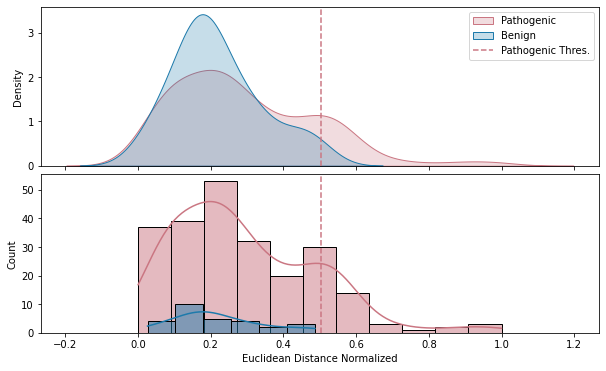

In [17]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean_pillar"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()
axes[0].set_ylabel('Density')

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean_pillar"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean_pillar"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
axes[1].set_ylabel('Count')

plt.subplots_adjust(hspace=.05)
plt.show()

In [18]:
num_edge_filter = 1

benign_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores.shape)

path_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores.shape)

vus_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores.shape)

conf_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} VUS and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('normalized_euclid_distance_normalized') > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")

With this threshold, we capture 0 benign alleles at ~5% error rate, which is 0.00% of the benign alleles.
With this threshold, we capture 44 pathogenic alleles at ~5% error rate, which is 18.80% of the pathogenic alleles.
With this threshold, we classify 9 VUS and 5 conflicting alleles as pathogenic at ~5% error rate, which is 9.89% and 6.67% of the VUS and conflicting alleles, respectively.


In [19]:
scores_dedup = scores_dedup.rename({"normalized_euclid_distance_normalized": "ppi_score_final_euclidean"}).with_columns(
    (pl.col("ppi_score_final_euclidean") > 0.503).alias("ppi_hit")
)
scores_dedup.write_csv(f"{sqy2h_outputs_dir}/6_variants_perturbation_scores_automated_annotated.csv")

In [ ]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,ppi_score_final_euclidean,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,bool
0.605295,0.492101,-0.857843,0.492101,9.425603,9.425603,3.236585,3.236585,null,3.368727,2,true,1.0,-0.422274,-0.875875,0.0255,0.058405,0.106094,false,false,0.480679,true,false,1.0,0.428008,2.38205,0.539611,"""KCNJ2""","""Ala70Thr""","""208G>A""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",0.000005,2.0,"""KCNJ2_Ala70Thr""",100016069,2606,"""KCNJ2""","""Ala70Thr""","""ENSG00000123700""","""4_VUS""",0.000005,2.0,true
0.531921,0.404532,-0.734836,0.404532,6.276117,6.276117,2.649872,2.649872,null,2.912056,2,true,1.0,-0.374961,-0.787751,0.074833,0.065463,0.159334,false,false,0.480679,true,false,1.0,0.376125,2.059135,0.474199,"""KCNJ2""","""Pro415Leu""","""1244C>T""","""ENSG00000123700""","""Edgotyping3""","""3_Conflicting""",0.000124,1.0,"""KCNJ2_Pro415Leu""",100016069,2659,"""KCNJ2""","""Pro415Leu""","""ENSG00000123700""","""3_Conflicting""",0.000124,1.0,false
0.218,0.218,-0.472012,0.218,1.893982,1.893982,0.921423,0.921423,null,0.989683,1,false,0.0,-0.218,-0.472012,null,0.243852,0.527988,false,true,0.461852,false,true,0.0,0.218,0.989683,0.274843,"""AGXT""","""Ala210Pro""","""628G>C""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ala210Pro""",70497,3848,"""AGXT""","""Ala210Pro""","""ENSG00000172482""","""1_Pathogenic""",null,null,false
0.076885,0.076885,-0.157806,0.076885,1.187375,1.187375,0.247776,0.247776,null,1.929022,1,false,0.0,-0.076885,-0.157806,null,0.410325,0.842194,true,false,0.48721,false,true,0.0,0.076885,1.929022,0.096932,"""CHN1""","""Pro252Ser""","""754C>T""","""ENSG00000128656""","""CEGS2""","""4_VUS""",null,1.0,"""CHN1_Pro252Ser""",3020,214470,"""CHN1""","""Pro252Ser""","""ENSG00000128656""","""4_VUS""",null,1.0,false
0.632821,0.584044,-0.621766,0.584044,7.999623,7.999623,2.999932,2.999932,null,3.075159,3,true,1.0,-0.307881,-0.766773,0.13056,0.048621,0.125006,false,false,0.380434,true,false,1.0,0.36536,1.775444,0.460627,"""ACSF3""","""Pro285Leu""","""854C>T""","""ENSG00000176715""","""Edgotyping3""","""2_Benign""",0.01414,2.0,"""ACSF3_Pro285Leu""",71337,3950,"""ACSF3""","""Pro285Leu""","""ENSG00000176715""","""2_Benign""",0.01414,2.0,false
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.593525,0.579564,-0.468828,0.579564,6.815226,6.815226,2.768762,2.768762,null,2.381105,2,false,0.5,-0.35377,-0.661049,0.271841,0.099663,0.14673,false,false,0.476099,false,false,0.5,0.419686,1.683695,0.529118,"""IL36RN""","""Thr123Arg""","""368C>G""","""ENSG00000136695""","""CEGS2""","""1_Pathogenic""",6.8417e-7,null,"""IL36RN_Thr123Arg""",8151,202847,"""IL36RN""","""Thr123Arg""","""ENSG00000136695""","""1_Pathogenic""",6.8417e-7,null,true
0.145282,-0.145282,0.638256,0.145282,0.610405,0.610405,-0.712161,0.712161,null,1.066425,1,false,0.0,0.145282,0.638256,null,0.372905,1.638256,true,false,0.227623,false,true,0.0,0.145282,1.066425,0.183164,"""TTR""","""Phe53Ile""","""157T>A""","""ENSG00000118271""","""CEGS2""","""1_Pathogenic""",null,null,"""TTR_Phe53Ile""",8999,202979,

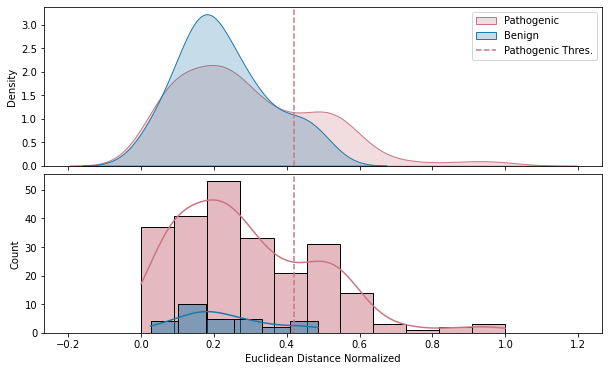

In [ ]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
plt.subplots_adjust(hspace=.05)
plt.show()

In [ ]:
manual_thresh = 0.42

num_edge_filter = 1

benign_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores.shape)

path_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores.shape)

vus_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores.shape)

conf_scores = scores_dedup.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores.shape)

print(f"With this threshold, we capture {benign_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} benign alleles at ~5% error rate, which is {benign_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / benign_scores.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / path_scores.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} VUS and {conf_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / vus_scores.shape[0] * 100:.2f}% and {conf_scores.filter(pl.col('ppi_score_final_euclidean') > manual_thresh).shape[0] / conf_scores.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")

With this threshold, we capture 3 benign alleles at ~5% error rate, which is 10.71% of the benign alleles.
With this threshold, we capture 62 pathogenic alleles at ~5% error rate, which is 26.50% of the pathogenic alleles.
With this threshold, we classify 19 VUS and 12 conflicting alleles as pathogenic at ~5% error rate, which is 20.88% and 16.00% of the VUS and conflicting alleles, respectively.


# exploring scores

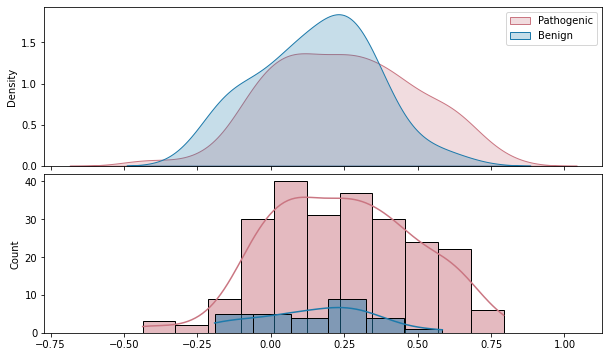

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

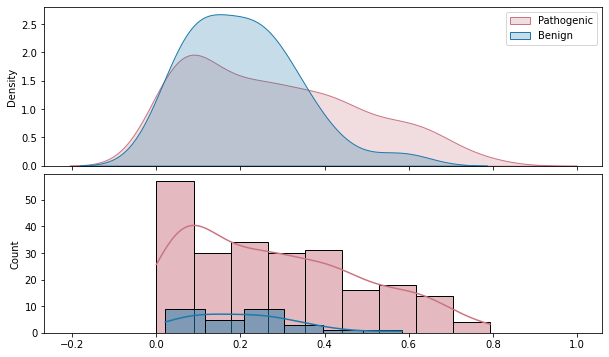

In [ ]:
path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation_abs"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation_abs"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_perturbation_abs"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_perturbation_abs"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

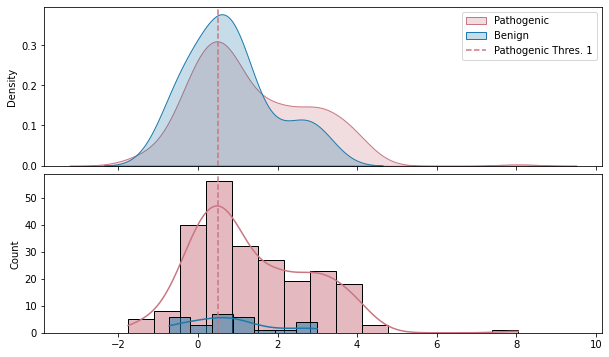

In [ ]:

path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
axes[0].legend()

sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["max_log2_fold_change"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["max_log2_fold_change"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres. 1')
plt.subplots_adjust(hspace=.05)
plt.show()

# summarizing plots

In [ ]:
scores_dedup = scores_dedup.with_columns(
    (pl.col("ppi_score_final_euclidean") > 0.42).alias("ppi_hit_manual"),
)

In [ ]:
scores_dedup

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_mahal_distance_reg,ppi_score_final_euclidean,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,ppi_hit,ppi_hit_manual
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,bool,bool
0.605295,0.492101,-0.857843,0.492101,9.425603,9.425603,3.236585,3.236585,null,3.368727,2,true,1.0,-0.422274,-0.875875,0.0255,0.058405,0.106094,false,false,0.480679,true,false,1.0,0.428008,2.38205,0.539611,"""KCNJ2""","""Ala70Thr""","""208G>A""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",0.000005,2.0,"""KCNJ2_Ala70Thr""",100016069,2606,"""KCNJ2""","""Ala70Thr""","""ENSG00000123700""","""4_VUS""",0.000005,2.0,true,true
0.531921,0.404532,-0.734836,0.404532,6.276117,6.276117,2.649872,2.649872,null,2.912056,2,true,1.0,-0.374961,-0.787751,0.074833,0.065463,0.159334,false,false,0.480679,true,false,1.0,0.376125,2.059135,0.474199,"""KCNJ2""","""Pro415Leu""","""1244C>T""","""ENSG00000123700""","""Edgotyping3""","""3_Conflicting""",0.000124,1.0,"""KCNJ2_Pro415Leu""",100016069,2659,"""KCNJ2""","""Pro415Leu""","""ENSG00000123700""","""3_Conflicting""",0.000124,1.0,false,true
0.218,0.218,-0.472012,0.218,1.893982,1.893982,0.921423,0.921423,null,0.989683,1,false,0.0,-0.218,-0.472012,null,0.243852,0.527988,false,true,0.461852,false,true,0.0,0.218,0.989683,0.274843,"""AGXT""","""Ala210Pro""","""628G>C""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ala210Pro""",70497,3848,"""AGXT""","""Ala210Pro""","""ENSG00000172482""","""1_Pathogenic""",null,null,false,false
0.076885,0.076885,-0.157806,0.076885,1.187375,1.187375,0.247776,0.247776,null,1.929022,1,false,0.0,-0.076885,-0.157806,null,0.410325,0.842194,true,false,0.48721,false,true,0.0,0.076885,1.929022,0.096932,"""CHN1""","""Pro252Ser""","""754C>T""","""ENSG00000128656""","""CEGS2""","""4_VUS""",null,1.0,"""CHN1_Pro252Ser""",3020,214470,"""CHN1""","""Pro252Ser""","""ENSG00000128656""","""4_VUS""",null,1.0,false,false
0.632821,0.584044,-0.621766,0.584044,7.999623,7.999623,2.999932,2.999932,null,3.075159,3,true,1.0,-0.307881,-0.766773,0.13056,0.048621,0.125006,false,false,0.380434,true,false,1.0,0.36536,1.775444,0.460627,"""ACSF3""","""Pro285Leu""","""854C>T""","""ENSG00000176715""","""Edgotyping3""","""2_Benign""",0.01414,2.0,"""ACSF3_Pro285Leu""",71337,3950,"""ACSF3""","""Pro285Leu""","""ENSG00000176715""","""2_Benign""",0.01414,2.0,false,true
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.593525,0.579564,-0.468828,0.579564,6.815226,6.815226,2.768762,2.768762,null,2.381105,2,false,0.5,-0.35377,-0.661049,0.271841,0.099663,0.14673,false,false,0.476099,false,false,0.5,0.419686,1.683695,0.529118,"""IL36RN""","""Thr123Arg""","""368C>G""","""ENSG00000136695""","""CEGS2""","""1_Pathogenic""",6.8417e-7,null,"""IL36RN_Thr123Arg""",8151,202847,"""IL36RN""","""Thr123Arg""","""ENSG00000136695""","""1_Pathogenic""",6.8417e-7,null,true,true
0.145282,-0.145282,0.638256,0.145282,0.610405,0.610405,-0.712161,0.712161,null,1.066425,1,false,0.0,0.145282,0.638256,null,0.372905,1.638256,true,false,0.227623,false,true,0.0,0.145282,1.066425,0.183164,"""TTR""","""Phe53Ile""","""157T>A""","""ENSG00000118271""","""CEGS2""","""1_P

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_13960/2621764279.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxenplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_13960/2621764279.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=30)


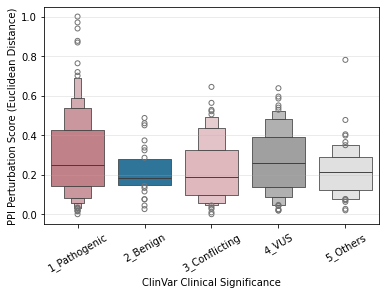

In [20]:
order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]

ax = sns.boxenplot(
    data=scores_dedup,
    x="clinvar_clnsig_clean",
    y="ppi_score_final_euclidean",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pillar"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_13960/1844317704.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_13960/1844317704.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'], rotation=30)


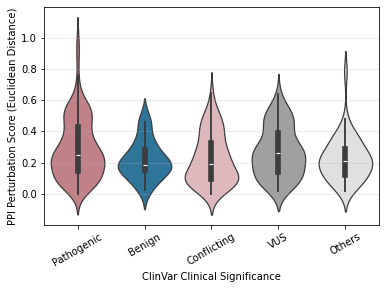

In [22]:
order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]

ax = sns.violinplot(
    data=scores_dedup,
    x="clinvar_clnsig_clean",
    y="ppi_score_final_euclidean",
    order=order,
    palette=palette_dict["clinvar_clnsig_clean_pillar"],
)
ax.grid(alpha=0.3, axis='y')
ax.set_xticklabels(['Pathogenic', 'Benign', 'Conflicting', 'VUS', 'Others'], rotation=30)
ax.set_ylabel("PPI Perturbation Score (Euclidean Distance)")
ax.set_xlabel("ClinVar Clinical Significance")
plt.show()


In [ ]:
inh_mapping_df = pd.read_csv(f"{metadata_outputs_dir}/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", sep="\t")
inh_mapping_df

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_39908/3209990772.py:1: DtypeWarning: Columns (104,106,139,142,158,159,161,162,164,166,188,190,191,193,194,196,197,200,211,218,219,231,232,242,243,244,255,256,259,260) have mixed types. Specify dtype option on import or set low_memory=False.
  inh_mapping_df = pd.read_csv(f"{metadata_outputs_dir}/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv", sep="\t")


,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,2.0,1_Pathogenic,98.91,0.225806,"['608013', '230800', '230900', '231000', '2310...",multiple,OMIM,NaN,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,2.0,1_Pathogenic,98.39,0.097561,"['230900', '230800', '231000', '168600', '6080...",multiple,OMIM,NaN,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,2.0,1_Pathogenic,98.35,0.052419,"['230800', '127750', '168600']",multiple,OMIM,NaN,0,"GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7493,SRY,ENSG00000184895,100070152,229149.0,CCSBVarC007069,ALE00007067,NC_000024.10:2787412:C:T,192G>A,Met64Ile,CEGS2,...,1.0,1_Pathogenic,97.60,0.351064,['400044'],y-linked,OMIM,Rare genetic gynecological and obstetrical dis...,8,"46,XY SEX REVERSAL 1"
7494,SRY,ENSG00000184895,100070152,229151.0,CCSBVarC007072,ALE00007070,NC_000024.10:2787267:C:T,337G>A,Ala113Thr,CEGS2,...,NaN,1_Pathogenic,98.35,0.113208,['400044'],y-linked,OMIM,Rare genetic gynecological and obstetrical dis...,8,"46,XY SEX REVERSAL 1"
7495,SRY,ENSG00000184895,100070152,229152.0,CCSBVarC007068,ALE00007066,NC_000024.10:2787207:G:A,397C>T,Arg133Trp,CEGS2,...,NaN,1_Pathogenic,93.67,0.963710,['400044'],y-linked,OMIM,Rare genetic gynecological and obstetrical dis...,8,"46,XY SEX REVERSAL 1"
7496,CTNNB1,ENSG00000168036,100070227,212487.0,CCSBVarC007073,ALE00007071,NC_000003.12:41225785:A:G,860A>G,Asn287Ser,CEGS2,...,2.0,2_Benign,96.60,0.821656,['114550'],somatic mutation,OMIM,Rare genetic eye disease; Rare genetic develop...,4,HEPATOCELLULAR CARCINOMA


In [ ]:
mapping_dict = inh_mapping_df.set_index('gene_variant')['inheritance_pattern'].to_dict()
mapping_dict

{'GBA1_Val54Leu': nan,
 'GBA1_Leu224Phe': nan,
 'GBA1_Arg296Gln': 'multiple',
 'GBA1_Leu483Pro': 'multiple',
 'GBA1_Arg87Trp': 'multiple',
 'GBA1_Arg159Gln': 'autosomal recessive',
 'GBA1_Lys196Gln': 'autosomal recessive',
 'GBA1_Arg209Cys': 'autosomal recessive',
 'GBA1_Trp223Arg': 'autosomal recessive',
 'GBA1_Arg202Gln': nan,
 'GBA1_Phe252Ile': 'multiple',
 'GBA1_Asn227Ser': 'autosomal recessive',
 'GBA1_His294Gln': 'autosomal recessive',
 'GBA1_Phe290Leu': 'autosomal recessive',
 'GBA1_Pro328Leu': 'autosomal recessive',
 'GBA1_Phe255Val': 'autosomal recessive',
 'GBA1_Thr362Ile': 'autosomal recessive',
 'GBA1_Asp354His': nan,
 'GBA1_His350Arg': 'autosomal recessive',
 'GBA1_Asn409Ser': 'multiple',
 'GBA1_Asp448Val': 'autosomal recessive',
 'GBA1_Val414Leu': 'autosomal recessive',
 'GBA1_Asp482Asn': 'multiple',
 'GBA1_Ala495Pro': nan,
 'GBA1_Leu483Arg': 'autosomal recessive',
 'GBA1_Gly517Ser': 'autosomal recessive',
 'GBA1_Arg535His': 'multiple',
 'NHERF1_Leu110Val': 'autosomal dom

In [ ]:

scores_dedup_pd['inheritance_pattern'] = scores_dedup_pd['allele_0'].map(mapping_dict)
scores_dedup_pd

,euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,...,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,inheritance_pattern
0,0.418184,0.269566,0.222505,0.269566,1.580485,1.580485,0.660368,0.660368,NaN,2.514850,...,KRT86_Glu402Gln,13939,204120,KRT86,Glu402Gln,ENSG00000170442,1_Pathogenic,0.000002,NaN,autosomal dominant
1,0.346905,0.234084,-0.257981,0.234084,1.672512,1.672512,0.742017,0.742017,NaN,2.614603,...,KRT6A_Tyr465His,4870,215293,KRT6A,Tyr465His,ENSG00000205420,1_Pathogenic,NaN,1.0,NaN
2,1.080148,0.675582,-0.504084,0.675582,15.450371,15.450371,3.949570,3.949570,NaN,4.427696,...,STXBP1_Arg235Gln,7652,1805,STXBP1,Arg235Gln,ENSG00000136854,1_Pathogenic,NaN,2.0,multiple
3,1.508855,0.619426,-0.608607,0.619426,89.392061,89.392061,6.482075,6.482075,NaN,4.440366,...,MLH1_Ile36Asn,2713,200798,MLH1,Ile36Asn,ENSG00000076242,4_VUS,NaN,1.0,NaN
4,0.359863,0.237655,-0.257482,0.237655,1.885134,1.885134,0.914667,0.914667,NaN,2.209522,...,NMNAT1_Glu257Lys,7675,202585,NMNAT1,Glu257Lys,ENSG00000173614,1_Pathogenic,0.001030,2.0,autosomal recessive
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
470,0.379185,0.367187,0.342721,0.367187,2.222752,2.222752,1.152347,1.152347,NaN,2.739786,...,ACSF3_Thr358Ile,71337,205771,ACSF3,Thr358Ile,ENSG00000176715,4_VUS,NaN,2.0,autosomal recessive
471,0.983948,0.772331,-0.781202,0.772331,inf,inf,inf,inf,NaN,5.037895,...,HPRT1_Ile132Met,7982,202799,HPRT1,Ile132Met,ENSG00000165704,1_Pathogenic,NaN,NaN,x-linked recessive
472,0.108788,0.103450,0.073515,0.103450,1.525772,1.525772,0.609540,0.609540,NaN,1.174686,...,SMAD3_Arg323His,11805,2167,SMAD3,Arg323His,ENSG00000166949,3_Conflicting,0.000013,1.0,NaN
473,0.123609,-0.123609,0.372054,0.123609,0.728834,0.728834,-0.456337,0.456337,NaN,1.236193,...,GALE_Val94Met,2767,214357,GALE,Val94Met,ENSG00000117308,1_Pathogenic,0.000060,2.0,autosomal recessive


In [ ]:
scores_dedup_pd.clinvar_clnsig_clean_right.value_counts()

clinvar_clnsig_clean_right
1_Pathogenic     234
4_VUS             91
3_Conflicting     75
5_Others          42
2_Benign          28
6_No_ClinVar       5
Name: count, dtype: int64

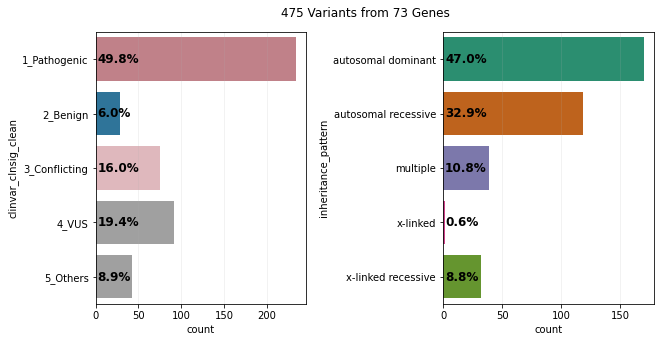

In [ ]:
original_df = pl.DataFrame(scores_dedup_pd)

plot_df = scores_dedup_pd[scores_dedup_pd.clinvar_clnsig_clean_right.isin(['1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS', '5_Others'])]


scores_dedup_pl = pl.DataFrame(plot_df)


fig, axes = plt.subplots(1,2,figsize=(10,5))
plot_cat_count_perc(
    scores_dedup_pl,
    "clinvar_clnsig_clean",
    title="ClinVar",
    ax=axes[0],
    palette=palette_dict["clinvar_clnsig_clean"]
)
plot_df = plot_df[plot_df.inheritance_pattern.isin(['autosomal dominant', 'autosomal recessive', 'multiple', 'x-linked', 'x-linked recessive'])]

scores_dedup_pl = pl.DataFrame(plot_df)
plot_cat_count_perc(
    scores_dedup_pl,
    "inheritance_pattern",
    title="Inheritance",
    ax=axes[1],
)

plt.suptitle(f"{original_df.unique('allele_0').shape[0]} Variants from {original_df.unique('symbol').shape[0]} Genes", y=.95)
plt.subplots_adjust(wspace=.65)
plt.show()

In [ ]:
scores_dedup_pl

euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,orf_id,mut_id,symbol_right,aa_change_right,ensembl_gene_id_right,clinvar_clnsig_clean_right,gnomad_af_right,StarStatus_right,inheritance_pattern
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,i64,i64,str,str,str,str,f64,f64,str
0.418184,0.269566,0.222505,0.269566,1.580485,1.580485,0.660368,0.660368,null,2.51485,7,false,0.0,-0.11568,-0.157968,0.193233,0.46438,0.632717,false,false,0.626684,false,true,0.0,0.158059,0.199272,"""KRT86""","""Glu402Gln""","""1204G>C""","""ENSG00000170442""","""CEGS2""","""1_Pathogenic""",0.000002,null,"""KRT86_Glu402Gln""",13939,204120,"""KRT86""","""Glu402Gln""","""ENSG00000170442""","""1_Pathogenic""",0.000002,null,"""autosomal dominant"""
1.080148,0.675582,-0.504084,0.675582,15.450371,15.450371,3.94957,3.94957,null,4.427696,5,true,1.0,-0.443965,-0.7535,0.156092,0.046752,0.064723,false,false,0.559794,true,false,1.0,0.483057,0.609013,"""STXBP1""","""Arg235Gln""","""704G>A""","""ENSG00000136854""","""Edgotyping3""","""1_Pathogenic""",null,2.0,"""STXBP1_Arg235Gln""",7652,1805,"""STXBP1""","""Arg235Gln""","""ENSG00000136854""","""1_Pathogenic""",null,2.0,"""multiple"""
0.359863,0.237655,-0.257482,0.237655,1.885134,1.885134,0.914667,0.914667,null,2.209522,3,false,0.0,-0.206179,-0.346213,0.110176,0.232771,0.530466,false,true,0.626837,false,true,0.0,0.207767,0.261942,"""NMNAT1""","""Glu257Lys""","""769G>A""","""ENSG00000173614""","""CEGS2""","""1_Pathogenic""",0.0010295,2.0,"""NMNAT1_Glu257Lys""",7675,202585,"""NMNAT1""","""Glu257Lys""","""ENSG00000173614""","""1_Pathogenic""",0.0010295,2.0,"""autosomal recessive"""
0.301868,0.296525,-0.155965,0.296525,3.736625,3.736625,1.901736,1.901736,null,2.697025,2,false,0.5,-0.176534,-0.444172,0.407586,0.108354,0.267621,false,false,0.383707,false,false,0.5,0.213453,0.26911,"""TMEM43""","""Glu142Lys""","""424G>A""","""ENSG00000170876""","""CEGS2""","""3_Conflicting""",0.00109,1.0,"""TMEM43_Glu142Lys""",3438,201179,"""TMEM43""","""Glu142Lys""","""ENSG00000170876""","""3_Conflicting""",0.00109,1.0,"""autosomal dominant"""
0.14434,-0.041243,0.302098,0.041243,0.879212,0.879212,-0.185718,0.185718,null,0.738215,2,false,0.0,0.089783,0.21974,0.116471,0.341452,1.137383,true,false,0.37904,false,true,0.0,0.102064,0.128677,"""SMAD3""","""Met212Ile""","""636G>A""","""ENSG00000166949""","""Edgotyping3""","""3_Conflicting""",0.000131,1.0,"""SMAD3_Met212Ile""",11805,2136,"""SMAD3""","""Met212Ile""","""ENSG00000166949""","""3_Conflicting""",0.000131,1.0,"""autosomal dominant"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.907963,0.487934,4.141224,0.487934,7.914663,7.914663,2.984528,2.984528,null,4.551187,15,false,0.333333,-0.12641,-0.005711,1.206716,0.053816,0.126348,false,false,0.493621,false,false,0.333333,0.234435,0.295563,"""LITAF""","""Pro84Leu""","""251C>T""","""ENSG00000189067""","""Edgotyping3""","""4_VUS""",null,2.0,"""LITAF_Pro84Leu""",52920,2681,"""LITAF""","""Pro84Leu""","""ENSG00000189067""","""4_VUS""",0.000011,2.0,"""autosomal dominant"""
0.379185,0.367187,0.342721,0.367187,2.222752,2.222752,1.152347,1.152347,null,2.739786,3,false,0.333333,-0.080138,-0.007344,0.476587,0.268259,0.449893,false,false,0.380434,false,false,0.333333,0.218923,0.276007,"""ACSF3""","""Thr358Ile""",

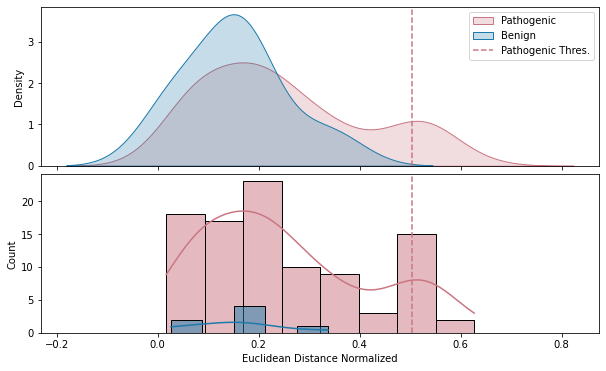

In [ ]:

path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic") & (pl.col('inheritance_pattern') == 'autosomal dominant'))["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="2_Benign") & (pl.col('inheritance_pattern') == 'autosomal dominant'))["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic") & (pl.col('inheritance_pattern') == 'autosomal dominant'))["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="2_Benign") & (pl.col('inheritance_pattern') == 'autosomal dominant'))["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
plt.subplots_adjust(hspace=.05)
plt.show()

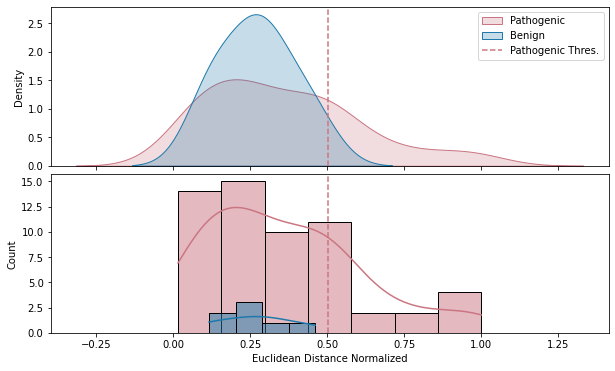

In [ ]:

path_thres = 0.503

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic") & (pl.col('inheritance_pattern') == 'autosomal recessive'))["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="2_Benign") & (pl.col('inheritance_pattern') == 'autosomal recessive'))["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic") & (pl.col('inheritance_pattern') == 'autosomal recessive'))["normalized_euclid_distance_normalized"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_dedup_pl.filter((pl.col("clinvar_clnsig_clean")=="2_Benign") & (pl.col('inheritance_pattern') == 'autosomal recessive'))["normalized_euclid_distance_normalized"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
plt.subplots_adjust(hspace=.05)
plt.show()

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""1_Pathogenic""",234,44,18.803419
"""2_Benign""",28,0,0.0
"""3_Conflicting""",75,5,6.666667
"""4_VUS""",91,9,9.89011
"""5_Others""",42,1,2.380952


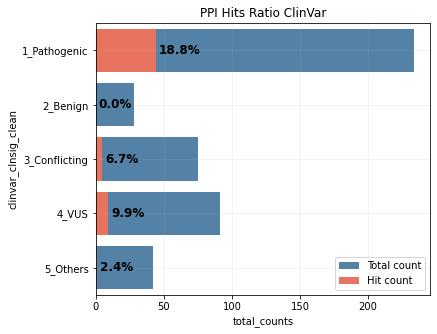

In [ ]:
# Add gene_variant column to match the function expectation
scores_dedup_with_gene_variant = scores_dedup.with_columns(
    pl.col("allele_0").alias("gene_allele")
)

scores_dedup_with_gene_variant = scores_dedup_with_gene_variant.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""1_Pathogenic""",234,62,26.495726
"""2_Benign""",28,3,10.714286
"""3_Conflicting""",75,12,16.0
"""4_VUS""",91,19,20.879121
"""5_Others""",42,2,4.761905


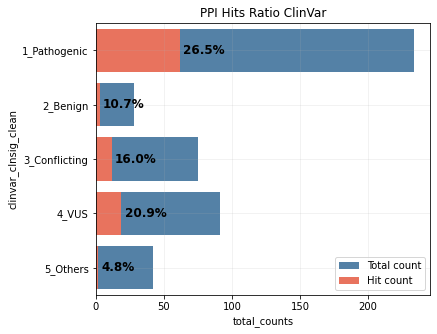

In [ ]:
# Add gene_variant column to match the function expectation
scores_dedup_with_gene_variant = scores_dedup.with_columns(
    pl.col("allele_0").alias("gene_allele")
)

scores_dedup_with_gene_variant = scores_dedup_with_gene_variant.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_dedup_with_gene_variant, "ppi_hit_manual", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")

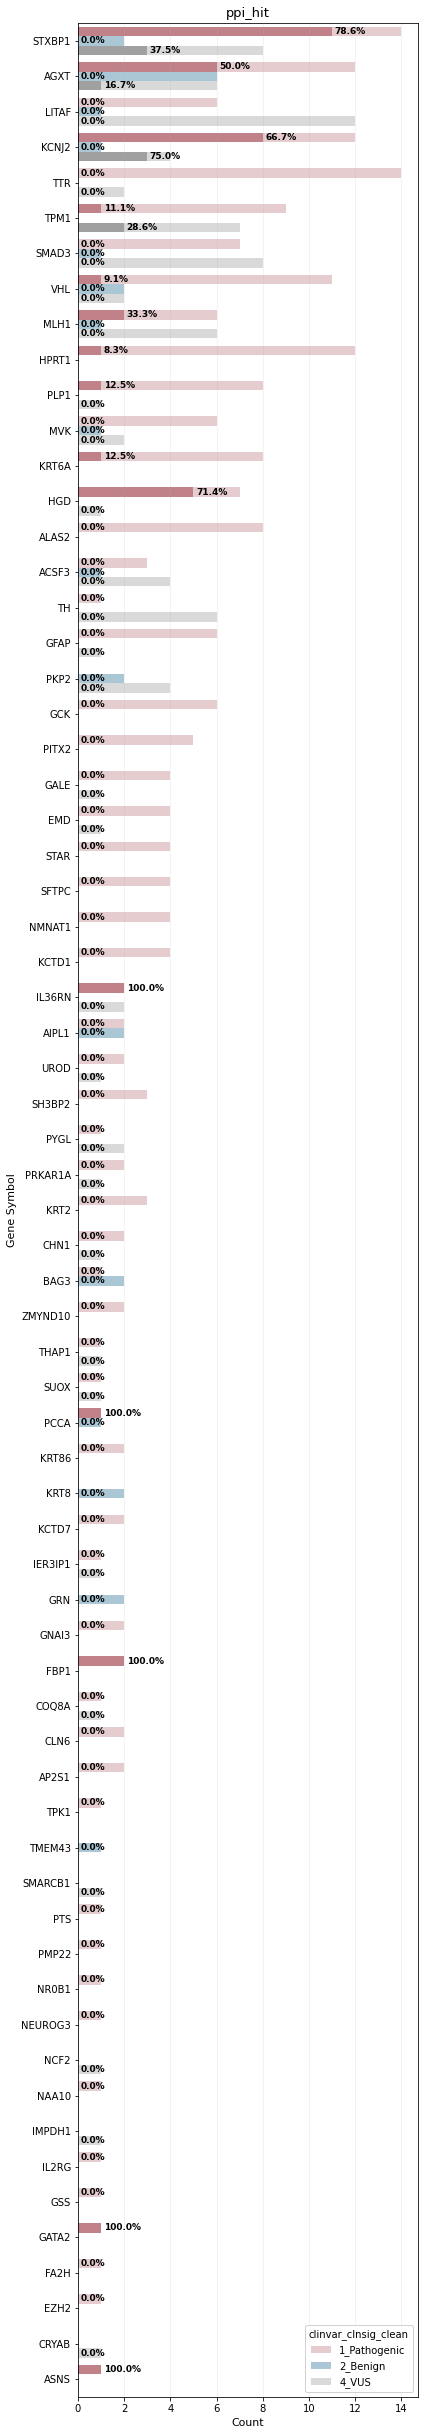

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,STXBP1,1_Pathogenic,14,11,78.571429,24
1,STXBP1,2_Benign,2,0,0.000000,24
2,STXBP1,4_VUS,8,3,37.500000,24
3,AGXT,1_Pathogenic,12,6,50.000000,24
4,AGXT,2_Benign,6,0,0.000000,24
...,...,...,...,...,...,...
101,GATA2,1_Pathogenic,1,1,100.000000,1
102,FA2H,1_Pathogenic,1,0,0.000000,1
103,EZH2,1_Pathogenic,1,0,0.000000,1
104,CRYAB,4_VUS,1,0,0.000000,1


In [ ]:
plot_gene_level_summary(
    assay_df=scores_dedup_with_gene_variant.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="ppi_hit",
    palette=palette_dict["clinvar_clnsig_clean"]
)

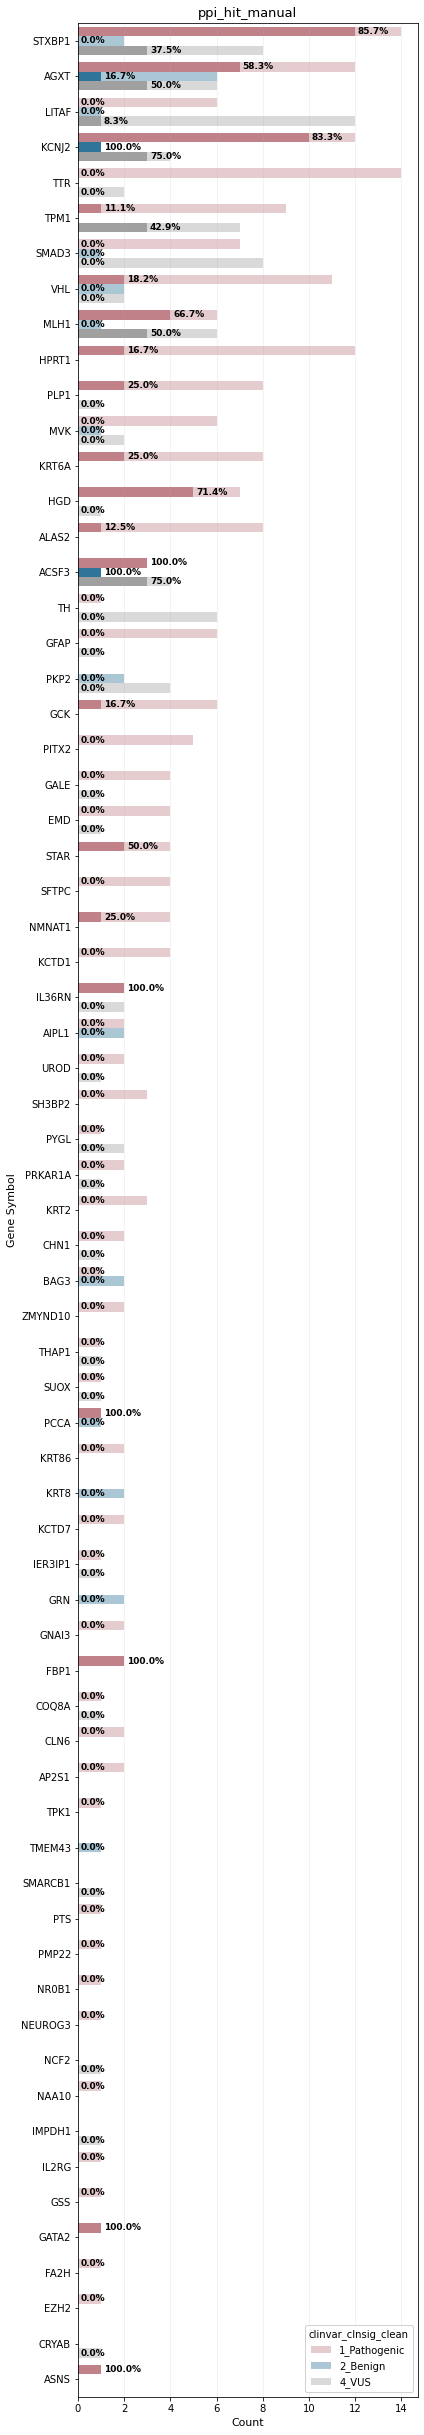

,symbol,clinvar_clnsig_clean,total_counts,hit_counts,hit_perc,total_counts_all
0,STXBP1,1_Pathogenic,14,12,85.714286,24
1,STXBP1,2_Benign,2,0,0.000000,24
2,STXBP1,4_VUS,8,3,37.500000,24
3,AGXT,1_Pathogenic,12,7,58.333333,24
4,AGXT,2_Benign,6,1,16.666667,24
...,...,...,...,...,...,...
101,GATA2,1_Pathogenic,1,1,100.000000,1
102,FA2H,1_Pathogenic,1,0,0.000000,1
103,EZH2,1_Pathogenic,1,0,0.000000,1
104,CRYAB,4_VUS,1,0,0.000000,1


In [ ]:
plot_gene_level_summary(
    assay_df=scores_dedup_with_gene_variant.filter(
        pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","4_VUS"])
    ),
    assay="ppi_hit_manual",
    palette=palette_dict["clinvar_clnsig_clean"]
)

# LWH1

In [ ]:
scores_lwh1 = scores_lwh1.filter(pl.col("normalized_euclid_distance_normalized_lwh1").is_not_null())

In [ ]:
scores_lwh1.to_pandas().symbol.nunique()

64

In [ ]:
scores_lwh1.to_pandas().mut_id.nunique()

398

In [ ]:

scores_lwh1.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance_normalized_lwh1").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance_normalized_lwh1", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_referenceSet.csv")

scores_lwh1.with_columns(
    pl.col("normalized_euclid_distance_normalized_lwh1").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_allscores.csv")
scores_lwh1


euclid_distance,max_perturbation,max_relative_perturbation,max_perturbation_abs,max_perturbation_fold,max_perturbation_fold_abs,max_log2_fold_change,max_log2_fold_change_abs,mahalanobis_distance,mahalanobis_distance_reg,num_edges,all_edges_severely_perturbed,fraction_severely_perturbed,mean_perturbation,mean_relative_perturbation,std_relative_perturbation,min_edge_value,min_relative_edge_value,no_edges_perturbed,inconclusive,mean_wt,log2fc_perturbed,log2fc_no_perturbed,fraction_log2fc_perturbed,normalized_euclid_distance,normalized_euclid_distance_normalized,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,variant_class,variant_class_log2fc,lwh1_normalized_euclid_distance,lwh1_log2fc_perturbed,lwh1_log2fc_no_perturbed,lwh1_fraction_log2fc_perturbed,variant_class_log2fc_lwh1,orf_id,mut_id,normalized_euclid_distance_normalized_lwh1
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool,f64,f64,f64,str,str,str,str,str,str,f64,f64,str,str,str,f64,bool,bool,f64,str,i64,i64,f64
0.035523,0.035523,-0.088319,0.035523,1.096875,1.096875,0.133399,0.133399,null,0.287211,1,false,0.0,-0.035523,-0.088319,null,0.366692,0.911681,true,false,0.402215,false,true,0.0,0.035523,0.044786,"""PKP2""","""Asp26Asn""","""76G>A""","""ENSG00000057294""","""Edgotyping3""","""2_Benign""",null,2.0,"""PKP2_Asp26Asn""","""QW""","""QW""",62.392168,false,true,0.0,"""QW""",54308,3142,0.107113
0.071094,0.071094,-0.364746,0.071094,1.574175,1.574175,0.654596,0.654596,null,0.957641,1,false,0.0,-0.071094,-0.364746,null,0.123819,0.635254,false,true,0.194913,false,true,0.0,0.071094,0.089632,"""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp""","""I""","""QW""",228.300988,false,true,0.0,"""QW""",281,744,0.391939
0.093574,0.061598,0.158845,0.061598,1.092988,1.092988,0.128278,0.128278,null,0.611345,2,false,0.0,0.004421,0.036884,0.172479,0.513894,0.914923,true,false,0.583741,false,true,0.0,0.066167,0.08342,"""TPM1""","""Glu40Lys""","""118G>A""","""ENSG00000140416""","""RC4""","""4_VUS""",null,1.0,"""TPM1_Glu40Lys""","""QW""","""QW""",77.707537,false,true,0.0,"""QW""",4723,8945,0.133406
0.14735,0.14735,-0.501875,0.14735,2.007528,2.007528,1.00542,1.00542,null,0.987888,1,true,1.0,-0.14735,-0.501875,null,0.146249,0.498125,false,false,0.293599,true,false,1.0,0.14735,0.185771,"""AIPL1""","""Ala313Ser""","""937G>T""","""ENSG00000129221""","""CEGS2""","""3_Conflicting""",null,1.0,"""AIPL1_Ala313Ser""","""QN""","""QN""",132.178757,false,true,0.0,"""QW""",7167,216179,0.22692
0.537805,0.405126,-0.946834,0.405126,20.636944,20.636944,4.367157,4.367157,null,1.953848,2,true,1.0,-0.379415,-0.949188,0.00333,0.018012,0.048457,false,false,0.399796,true,false,1.0,0.380285,0.479444,"""STAR""","""Arg188Cys""","""562C>T""","""ENSG00000147465""","""CEGS2""","""1_Pathogenic""",null,2.0,"""STAR_Arg188Cys""","""QN""","""QN""",442.418073,true,false,1.0,"""QN""",386,213660,0.759527
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0.0873,0.034914,0.143337,0.034914,1.215799,1.215799,0.281905,0.281905,null,0.617833,2,false,0.0,0.02255,-0.017079,0.226863,0.161789,0.822504,true,false,0.377464,false,true,0.0,0.06173,0.077826,"""HBD""","""Gly26Asp""","""77G>A""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Gly26Asp""","""QW""","""QW""",25.543465,false,true,0.0,"""QW""",13796,218139,0.043852
0.397021,0.397021,-0.859629,0.397021,7.123992,7.123992,2.832686,2.832686,null,1.802413,1,true,1.0,-0.397021,-0.859629,null,0.064831,0.140371,false,false,0.461852,true,false,1.0,0.397021,0.500544,"""AGXT""","""Arg289Cys""","""865C>T""","""ENSG00000172482""","""Edgotyping3""","""4_VUS""",0.000456,2.0,"""AGXT_Arg289Cys""","""QN""","""QN""",417.372891,true,false,1.0,"""QN""",70497,3872,0.716531
0.255858,0.251423,-0.239168,0.251423,4.184375,4.184375,2.065012,2.065012,null,2.07653,2,false,0.5,-0.149428,-0.5

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-09-25_17:50:53 INFO: Reading input 
2025-09-25_17:50:53 INFO: Calculating densties 


Warning messages:
1: In stats::bw.bcv(data) : minimum occurred at one end of the range
2: In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-09-25_17:50:54 INFO: Drawing LLR plot 
2025-09-25_17:50:54 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-09-25_17:50:54 INFO: Category transitions:  
0.714 : none -> patho.support
0.875 : patho.support -> patho.moderate
0.926 : patho.moderate -> patho.strong
0.939 : patho.strong -> patho.vstrong
2025-09-25_17:50:54 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-09-25_17:50:54 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv.csv 
2025-09-25_17:50:54 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-09-25_17:51:00 INFO: Reading input 
2025-09-25_17:51:00 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-09-25_17:51:01 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


CalledProcessError: Command 'b'source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh\nconda activate py310\n\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_bcv.log" --bandwidth "bcv" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_allScores.csv ../3_outputs/sqY2H/PPI_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_LLR_default.log" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H

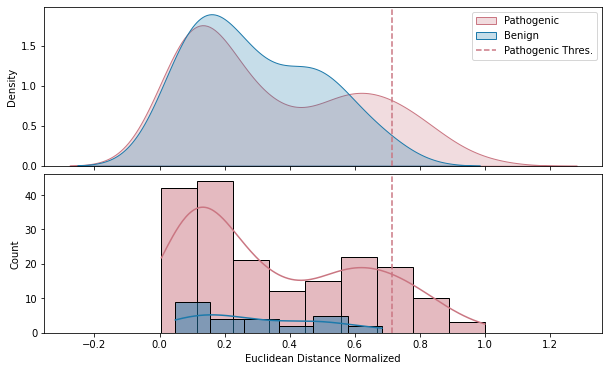

In [ ]:
path_thres = 0.714

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=scores_lwh1.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized_lwh1"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=scores_lwh1.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized_lwh1"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()
axes[0].set_ylabel('Density')

sns.histplot(scores_lwh1.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance_normalized_lwh1"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(scores_lwh1.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance_normalized_lwh1"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[1].set_xlabel('Euclidean Distance Normalized')
axes[1].set_ylabel('Count')

plt.subplots_adjust(hspace=.05)
plt.show()

In [ ]:
num_edge_filter = 1

benign_scores_lwh1 = scores_lwh1.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
# print(benign_scores_lwh1.shape)

path_scores_lwh1 = scores_lwh1.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
# print(path_scores_lwh1.shape)

vus_scores_lwh1 = scores_lwh1.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
# print(vus_scores_lwh1.shape)

conf_scores_lwh1 = scores_lwh1.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
# print(conf_scores_lwh1.shape)

print(f"With this threshold, we capture {benign_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0]} benign alleles at ~5% error rate, which is {benign_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0] / benign_scores_lwh1.shape[0] * 100:.2f}% of the benign alleles.")
print(f"With this threshold, we capture {path_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0]} pathogenic alleles at ~5% error rate, which is {path_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0] / path_scores_lwh1.shape[0] * 100:.2f}% of the pathogenic alleles.")
print(f"With this threshold, we classify {vus_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0]} VUS and {conf_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0]} conflicting alleles as pathogenic at ~5% error rate, which is {vus_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0] / vus_scores_lwh1.shape[0] * 100:.2f}% and {conf_scores_lwh1.filter(pl.col('normalized_euclid_distance_normalized_lwh1') > path_thres).shape[0] / conf_scores_lwh1.shape[0] * 100:.2f}% of the VUS and conflicting alleles, respectively.")

With this threshold, we capture 0 benign alleles at ~5% error rate, which is 0.00% of the benign alleles.
With this threshold, we capture 24 pathogenic alleles at ~5% error rate, which is 12.77% of the pathogenic alleles.
With this threshold, we classify 7 VUS and 5 conflicting alleles as pathogenic at ~5% error rate, which is 9.33% and 7.58% of the VUS and conflicting alleles, respectively.


In [ ]:
# ppi_hit for lwh1

scores_lwh1 = scores_lwh1.rename({"normalized_euclid_distance_normalized_lwh1": "ppi_score_final_euclidean_lwh1"}).with_columns(
    (pl.col("ppi_score_final_euclidean_lwh1") > path_thres).alias("ppi_hit_lwh1")
)

clinvar_clnsig_clean,total_counts,hit_counts,hit_perc
str,u32,u32,f64
"""1_Pathogenic""",188,24,12.765957
"""2_Benign""",26,0,0.0
"""3_Conflicting""",66,5,7.575758
"""4_VUS""",75,7,9.333333
"""5_Others""",39,1,2.564103


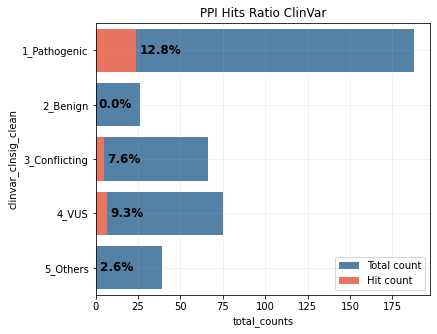

In [ ]:
# Add gene_variant column to match the function expectation
scores_lwh1 = scores_lwh1.with_columns(
    pl.col("allele_0").alias("gene_allele")
)

scores_lwh1 = scores_lwh1.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic","2_Benign","3_Conflicting","4_VUS","5_Others","6_No_ClinVar"]) #pl.col("Gene")!="BRCA1" #
)

plot_assay_hit_by_category(scores_lwh1, "ppi_hit_lwh1", "clinvar_clnsig_clean", f"PPI Hits Ratio ClinVar")